# UPI Transaction Fraud Detection & Model Evaluation

## Project objective
This notebook builds and evaluates baseline machine-learning models for classifying UPI transactions as **fraudulent (1)** or **not fraudulent (0)** using the fields available in the supplied dataset.

The workflow covers data validation, date-based feature creation, leakage-aware feature selection, stratified data splitting, preprocessing, model comparison, final evaluation, and saving the fitted pipeline.

**Important data note:** The supplied dataset contains 10,000 records and a very small fraud class (about 1%). The transaction date contains a calendar date but no time of day. The dataset does not provide device identifiers, beneficiary history, or account age, so this notebook does not create those fields. Treat the dataset and results as an analytical portfolio exercise, not evidence of production-ready fraud detection.


## 1. Import libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported.")

Libraries imported.


## 2. Load the dataset

The cell below checks several common project locations for the CSV file. If your file is stored elsewhere, update `DATA_PATH` to its location.


In [2]:
DATA_PATH = Path(r"C:\UPI Data\UPI_Transactions_Cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH.resolve())
print("Shape:", df.shape)
display(df.head())

Loaded: C:\UPI Data\UPI_Transactions_Cleaned.csv
Shape: (10000, 24)


,Transaction_ID,Transaction_Date,Customer_ID,City,State,Sender_Bank,Receiver_Bank,UPI_App,Transaction_Type,Payment_Method,Amount,Transaction_Status,Failure_Reason,Processing_Time_sec,Bank_Response_Time_ms,Fraud_Label,Year,Month,Month_Name,Day,Day_of_Week,Day_of_Week_Num,Is_Weekend,Quarter
0,TXN100000,2025-11-24,CUST09196,Bengaluru,Karnataka,SBI,Kotak Mahindra Bank,PhonePe,Online Purchase,Mobile Number,2014.53,Success,Not Applicable,4.83,801,0,2025,11,Nov,24,Monday,0,0,4
1,TXN100001,2025-04-23,CUST01520,Ahmedabad,Gujarat,Yes Bank,Kotak Mahindra Bank,BHIM,P2P,UPI ID,1359.97,Success,Not Applicable,1.58,751,0,2025,4,Apr,23,Wednesday,2,0,2
2,TXN100002,2025-06-26,CUST09460,Lucknow,Uttar Pradesh,Kotak Mahindra Bank,SBI,PhonePe,P2P,UPI,8199.06,Success,Not Applicable,3.03,816,0,2025,6,Jun,26,Thursday,3,0,2
3,TXN100003,2025-12-05,CUST05821,Mumbai,Maharashtra,Kotak Mahindra Bank,HDFC Bank,PhonePe,Bill Payment,UPI,2240.06,Success,Not Applicable,3.58,345,0,2025,12,Dec,5,Friday,4,0,4
4,TXN100004,2025-11-08,CUST00526,Kochi,Kerala,ICICI Bank,Union Bank,Paytm,Recharge,UPI ID,320.36,Success,Not Applicable,4.48,888,0,2025,11,Nov,8,Saturday,5,1,4


## 3. Validate the target and inspect the data

Before training, check that `Fraud_Label` exists and contains only the two expected values: `0` for non-fraud and `1` for fraud. This prevents the model from training on an incorrectly formatted target.


In [3]:
if "Fraud_Label" not in df.columns:
    raise ValueError("The dataset must contain a 'Fraud_Label' column.")

df = df.copy()
df["Fraud_Label"] = pd.to_numeric(df["Fraud_Label"], errors="coerce")
df = df.dropna(subset=["Fraud_Label"])
df["Fraud_Label"] = df["Fraud_Label"].astype(int)

if not set(df["Fraud_Label"].unique()).issubset({0, 1}):
    raise ValueError("Fraud_Label must contain only 0 (not fraud) and 1 (fraud).")

print("Shape after removing rows with missing target:", df.shape)
print("\nClass counts:")
display(df["Fraud_Label"].value_counts().rename(index={0: "Not fraud (0)", 1: "Fraud (1)"}).to_frame("Rows"))
print(f"Fraud rate: {df['Fraud_Label'].mean():.2%}")
print("\nMissing values:")
display(df.isna().sum().to_frame("Missing values"))

Shape after removing rows with missing target: (10000, 24)

Class counts:


,Rows
Fraud_Label,
Not fraud (0),9901
Fraud (1),99


Fraud rate: 0.99%

Missing values:


,Missing values
Transaction_ID,0
Transaction_Date,0
Customer_ID,0
City,0
State,0
Sender_Bank,0
Receiver_Bank,0
UPI_App,0
Transaction_Type,0
Payment_Method,0


## 4. Create available features and select predictors

The date column contains a date but no transaction time, so we can derive calendar features such as month, day of month, day of week, weekend, and quarter—but not hour of day.

The target (`Fraud_Label`) is never used as an input. Identifier columns are excluded from this baseline. `Transaction_Status` and `Failure_Reason` are also excluded because they may be known only after processing; using them could give the model information that would not be available at the time a fraud decision is meant to be made.

No unavailable device, beneficiary, account-age, location-change, or rolling transaction-history fields are fabricated.


In [4]:
if "Transaction_Date" in df.columns:
    parsed_date = pd.to_datetime(df["Transaction_Date"], errors="coerce")
    if parsed_date.notna().any():
        df["Transaction_Year"] = parsed_date.dt.year
        df["Transaction_Month"] = parsed_date.dt.month
        df["Transaction_Day"] = parsed_date.dt.day
        df["Day_of_Week_Num"] = parsed_date.dt.dayofweek  # Monday=0
        df["Is_Weekend"] = (parsed_date.dt.dayofweek >= 5).astype("Int64")
        df["Transaction_Quarter"] = parsed_date.dt.quarter

# Keep only features that really exist. No invented columns.
excluded_columns = {
    "Fraud_Label", "Transaction_ID", "Customer_ID", "Transaction_Date",
    "Transaction_Status", "Failure_Reason"
}
candidate_features = [c for c in df.columns if c not in excluded_columns]
features = [c for c in candidate_features if df[c].notna().any()]

if not features:
    raise ValueError("No usable predictor columns remain.")

X = df[features].copy()
y = df["Fraud_Label"].copy()

# Remove columns that contain no information at all.
constant_features = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
if constant_features:
    print("Dropping constant columns:", constant_features)
    X = X.drop(columns=constant_features)
    features = X.columns.tolist()

print("Predictor columns:")
print(features)
print("\nFeature matrix:", X.shape)
print("Target vector:", y.shape)

Dropping constant columns: ['Year', 'Transaction_Year']
Predictor columns:
['City', 'State', 'Sender_Bank', 'Receiver_Bank', 'UPI_App', 'Transaction_Type', 'Payment_Method', 'Amount', 'Processing_Time_sec', 'Bank_Response_Time_ms', 'Month', 'Month_Name', 'Day', 'Day_of_Week', 'Day_of_Week_Num', 'Is_Weekend', 'Quarter', 'Transaction_Month', 'Transaction_Day', 'Transaction_Quarter']

Feature matrix: (10000, 20)
Target vector: (10000,)


## 5. Split the data into training, validation, and test sets

- **Training set (60%)**: fits the candidate models.
- **Validation set (20%)**: compares candidates and selects one model.
- **Test set (20%)**: provides the final evaluation after model selection.

Stratification preserves approximately the same fraud proportion in each split. The test set is kept separate from model selection to reduce overly optimistic evaluation.


In [5]:
# 60% train, 20% validation, 20% test.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=RANDOM_STATE, stratify=y_dev
)

print(f"Train:      {len(X_train)} rows | fraud: {int(y_train.sum())}")
print(f"Validation: {len(X_val)} rows | fraud: {int(y_val.sum())}")
print(f"Test:       {len(X_test)} rows | fraud: {int(y_test.sum())}")

Train:      6000 rows | fraud: 59
Validation: 2000 rows | fraud: 20
Test:       2000 rows | fraud: 20


## 6. Build preprocessing pipelines

Machine-learning models need numerical inputs. This dataset includes both numbers (for example, amount and response time) and categories (for example, bank and payment method).

- Numerical missing values are filled with the training-set median; numerical features are standardized for Logistic Regression.
- Categorical missing values are filled with the most common training-set category; categories are converted into indicator columns using one-hot encoding.
- The transformations are inside a scikit-learn pipeline, so they are fitted on training data rather than on the full dataset. This helps prevent information from validation or test data leaking into preprocessing.


In [6]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Amount', 'Processing_Time_sec', 'Bank_Response_Time_ms', 'Month', 'Day', 'Day_of_Week_Num', 'Is_Weekend', 'Quarter', 'Transaction_Month', 'Transaction_Day', 'Transaction_Quarter']
Categorical features: ['City', 'State', 'Sender_Bank', 'Receiver_Bank', 'UPI_App', 'Transaction_Type', 'Payment_Method', 'Month_Name', 'Day_of_Week']


## 7. Train baseline and candidate models

Three approaches are compared:

- **Dummy Classifier:** a simple reference model that always predicts the most common class. It helps show why accuracy alone can be misleading.
- **Logistic Regression:** a relatively simple classification model. Balanced class weights make fraud mistakes count more during training.
- **Random Forest:** a collection of decision trees. Balanced class weights help account for the rarity of fraud.

These are baseline experiments, not a claim that any model is ready for real payment decisions.


In [7]:
models = {
    "Dummy baseline": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Dummy baseline
Trained: Logistic Regression
Trained: Random Forest


## 8. Compare models on the validation set

Because fraud is rare, compare models using **PR-AUC** (area under the precision–recall curve) rather than choosing only by accuracy. Precision tells us how many flagged transactions are actually fraud; recall tells us how many actual fraud cases the model catches.

The validation set is used for selection. The test set is not used to choose the model.


In [8]:
def evaluate_model(name, pipeline, X_eval, y_eval):
    y_pred = pipeline.predict(X_eval)
    y_prob = pipeline.predict_proba(X_eval)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Fraud Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Fraud Recall": recall_score(y_eval, y_pred, zero_division=0),
        "Fraud F1": f1_score(y_eval, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, y_prob) if y_eval.nunique() == 2 else np.nan,
        "PR-AUC (Average Precision)": average_precision_score(y_eval, y_prob)
    }

validation_results = pd.DataFrame([
    evaluate_model(name, model, X_val, y_val)
    for name, model in models.items()
]).sort_values("PR-AUC (Average Precision)", ascending=False)

display(validation_results.style.format({
    "Accuracy": "{:.3f}",
    "Fraud Precision": "{:.3f}",
    "Fraud Recall": "{:.3f}",
    "Fraud F1": "{:.3f}",
    "ROC-AUC": "{:.3f}",
    "PR-AUC (Average Precision)": "{:.3f}"
}))

best_model_name = validation_results.iloc[0]["Model"]
best_model = models[best_model_name]
print("Selected using validation PR-AUC:", best_model_name)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,ROC-AUC,PR-AUC (Average Precision)
0,Dummy baseline,0.990,0.000,0.000,0.000,0.500,0.010
1,Logistic Regression,0.703,0.010,0.300,0.020,0.441,0.009
2,Random Forest,0.989,0.000,0.000,0.000,0.349,0.007


Selected using validation PR-AUC: Dummy baseline


## 9. Evaluate the selected model on the test set

After selecting the candidate using validation results, fit it on the full development set (training + validation) and evaluate it on the untouched test set. These are the final held-out results for this experiment.


In [9]:
best_model.fit(X_dev, y_dev)
test_metrics = evaluate_model(best_model_name, best_model, X_test, y_test)
print("Final test metrics:")
display(pd.DataFrame([test_metrics]).style.format({
    "Accuracy": "{:.3f}",
    "Fraud Precision": "{:.3f}",
    "Fraud Recall": "{:.3f}",
    "Fraud F1": "{:.3f}",
    "ROC-AUC": "{:.3f}",
    "PR-AUC (Average Precision)": "{:.3f}"
}))

best_pred = best_model.predict(X_test)
print("\nClassification report at threshold 0.50:")
print(classification_report(
    y_test, best_pred,
    labels=[0, 1],
    target_names=["Not fraud", "Fraud"],
    zero_division=0
))

Final test metrics:


,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,ROC-AUC,PR-AUC (Average Precision)
0,Dummy baseline,0.990,0.000,0.000,0.000,0.500,0.010



Classification report at threshold 0.50:
              precision    recall  f1-score   support

   Not fraud       0.99      1.00      0.99      1980
       Fraud       0.00      0.00      0.00        20

    accuracy                           0.99      2000
   macro avg       0.49      0.50      0.50      2000
weighted avg       0.98      0.99      0.99      2000



## 10. Confusion matrix

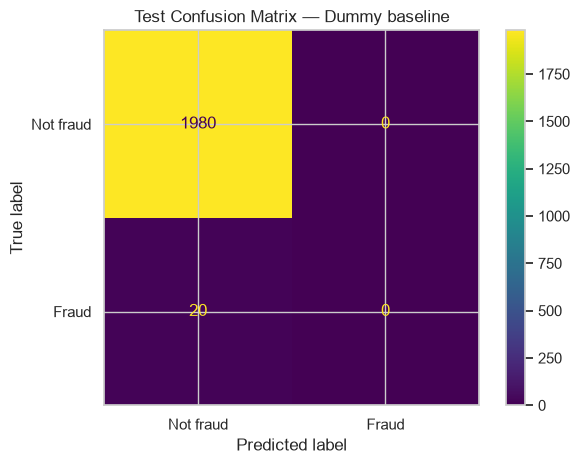

In [10]:
cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not fraud", "Fraud"])
disp.plot(values_format="d")
plt.title(f"Test Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## 11. Interpretation and limitations

- **Accuracy can mislead:** with only about 1% fraud, a model can score around 99% accuracy by predicting almost every transaction as non-fraud.
- **Precision:** among transactions flagged as fraud, the fraction that really are fraud.
- **Recall:** among all actual fraud transactions, the fraction the model detects.
- **F1-score:** combines precision and recall into one measure.
- **ROC-AUC:** measures how well the model ranks positive cases above negative cases across thresholds.
- **PR-AUC:** summarizes the precision–recall trade-off and is useful when the positive class is rare. Compare it with the fraud prevalence as a simple reference.
- **Limitations:** the dataset is synthetic, fraud cases are rare, and the available columns may not contain enough reliable signal to distinguish fraud. Results do not establish real-world performance or prove causal relationships.

Use these results as a baseline and as a reason to investigate data quality and label generation—not as a production fraud detector.


In [11]:
print("Test-set fraud prevalence (reference level for PR-AUC):", round(y_test.mean(), 4))
print("Test fraud cases:", int(y_test.sum()), "out of", len(y_test))
print("Model selected on validation data:", best_model_name)

Test-set fraud prevalence (reference level for PR-AUC): 0.01
Test fraud cases: 20 out of 2000
Model selected on validation data: Dummy baseline


## 12. Save the fitted model pipeline

The saved pipeline includes both preprocessing and the trained classifier. This means future data can go through the same transformations before a prediction is produced. The model file is saved in the local `models` folder.


In [14]:
MODEL_DIR = Path(r"C:\UPI Data\models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "upi_fraud_pipeline.joblib"

joblib.dump(best_model, model_path)

print("Saved successfully:", model_path.exists())
print("Full path:", model_path.resolve())

Saved successfully: True
Full path: C:\UPI Data\models\upi_fraud_pipeline.joblib


## 13. Demonstrate a sample prediction

This cell demonstrates the prediction interface using one row from the held-out test set. It is only an illustration on this dataset; it must not be interpreted as a real payment decision.


In [15]:
example_row = X_test.iloc[[0]].copy()
probability = best_model.predict_proba(example_row)[0, 1]
prediction = int(best_model.predict(example_row)[0])
print("Predicted class:", "Fraud" if prediction == 1 else "Not fraud")
print(f"Estimated model probability for fraud: {probability:.3f}")
print("This is a model score on synthetic data, not a real payment decision.")

Predicted class: Not fraud
Estimated model probability for fraud: 0.000
This is a model score on synthetic data, not a real payment decision.
